**Task Development of an End-to-End NLP Pipeline for Customer Feedback Intelligence and Sentiment Driven Decision Support**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("thedevastator/amazon-customer-reviews-with-2013-2019-sentiment")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'amazon-customer-reviews-with-2013-2019-sentiment' dataset.
Path to dataset files: /kaggle/input/amazon-customer-reviews-with-2013-2019-sentiment


In [ ]:
# Install required libraries
!pip install -q kagglehub nltk spacy wordcloud transformers datasets accelerate \
    sentence-transformers scikit-learn matplotlib seaborn pandas numpy tqdm
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 46.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, re, time, random, warnings, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
random.seed(42); np.random.seed(42)

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import spacy
from spacy.lang.en.stop_words import STOP_WORDS as SPACY_STOPWORDS

for pkg in ["punkt","punkt_tab","wordnet","stopwords","omw-1.4"]:
    nltk.download(pkg, quiet=True)

nlp = spacy.load("en_core_web_sm")
print("spaCy model loaded:", nlp.meta["name"], nlp.meta["version"])

spaCy model loaded: core_web_sm 3.8.0


In [ ]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13

In [ ]:
# Locate Load and inspect Dataset

DATA_DIR = "/kaggle/input/amazon-customer-reviews-with-2013-2019-sentiment"
print("Files in dataset dir:")
for f in os.listdir(DATA_DIR):
    print(" -", f)

# Use Csv
csv_path = os.path.join(DATA_DIR, [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")][0])
print("\nUsing:", csv_path)

df = pd.read_csv(csv_path, encoding="utf-8", on_bad_lines="skip")
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
df.head(5)

Files in dataset dir:
 - Amazon Review Data Web Scrapping - Amazon Review Data Web Scrapping.csv

Using: /kaggle/input/amazon-customer-reviews-with-2013-2019-sentiment/Amazon Review Data Web Scrapping - Amazon Review Data Web Scrapping.csv
Shape: (60889, 6)

Columns: ['Unique_ID', 'Category', 'Review_Header', 'Review_text', 'Rating', 'Own_Rating']


,Unique_ID,Category,Review_Header,Review_text,Rating,Own_Rating
0,136040,smartTv,Nice one,I liked it,5,Positive
1,134236,mobile,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,5,Positive
2,113945,books,Four Stars,"Awesome book at reasonable price, must buy ......",4,Positive
3,168076,smartTv,Nice quality,good,5,Positive
4,157302,books,Nice book,"The book is fine,not bad,contains nice concept...",3,Neutral


In [ ]:
# Basic info & missing values
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nSentiment class counts (Own_Rating):")
print(df["Own_Rating"].value_counts(dropna=False))

# Clean data issues

# Drop rows with no review text
df = df.dropna(subset=["Review_text"]).copy()
df["Review_text"] = df["Review_text"].astype(str)
df["Review_Header"] = df["Review_Header"].fillna("").astype(str)
df["Own_Rating"] = df["Own_Rating"].astype(str).str.strip()
df = df[df["Own_Rating"].isin(["Positive","Negative","Neutral"])].reset_index(drop=True)

print("After cleaning:", df.shape)
print(df["Own_Rating"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60889 entries, 0 to 60888
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unique_ID      60889 non-null  int64 
 1   Category       60889 non-null  object
 2   Review_Header  60884 non-null  object
 3   Review_text    60857 non-null  object
 4   Rating         60889 non-null  int64 
 5   Own_Rating     60889 non-null  object
dtypes: int64(2), object(4)
memory usage: 2.8+ MB

Missing values per column:
Unique_ID         0
Category          0
Review_Header     5
Review_text      32
Rating            0
Own_Rating        0
dtype: int64

Sentiment class counts (Own_Rating):
Own_Rating
Positive    47436
Negative     9087
Neutral      4366
Name: count, dtype: int64
After cleaning: (60857, 6)
Own_Rating
Positive    47407
Negative     9086
Neutral      4364
Name: count, dtype: int64


# Removed rows with missing reviews and kept only the three sentiment classes (Positive, Negative, Neutral). The dataset is strongly imbalanced (~78% Positive), which we will address later with class_weight='balanced' and macro-F1 reporting.

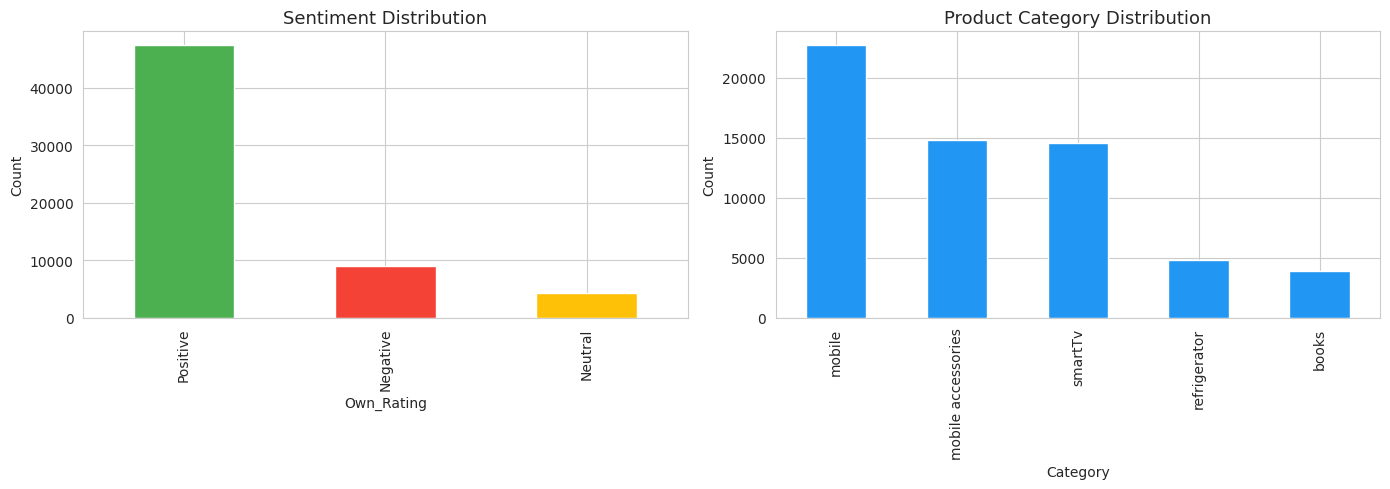

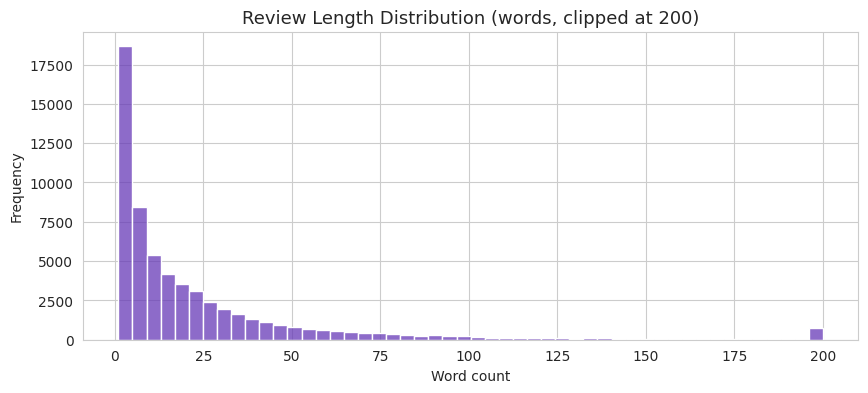

count    60857.000000
mean        25.571964
std         56.163437
min          1.000000
25%          3.000000
50%         11.000000
75%         28.000000
max       3318.000000
Name: raw_word_count, dtype: float64
RAW : I bought the phone on Amazon and been using my Samsung M30s for couple of weeks now. Delivery experience from Amazon - top notch. The best thing about the phone is its battery life. With normal usage,
NLTK: bought phone amazon using samsung couple week delivery experience amazon top notch best thing phone battery life normal usage battery work day lot gaming app usage still easily work day mah battery li
spaCy: buy phone amazon samsung couple week delivery experience amazon notch good thing phone battery life normal usage battery work day lot gaming app usage easily work day mah battery life problem super am
NLTK time: 1.7s | spaCy time: 93.9s


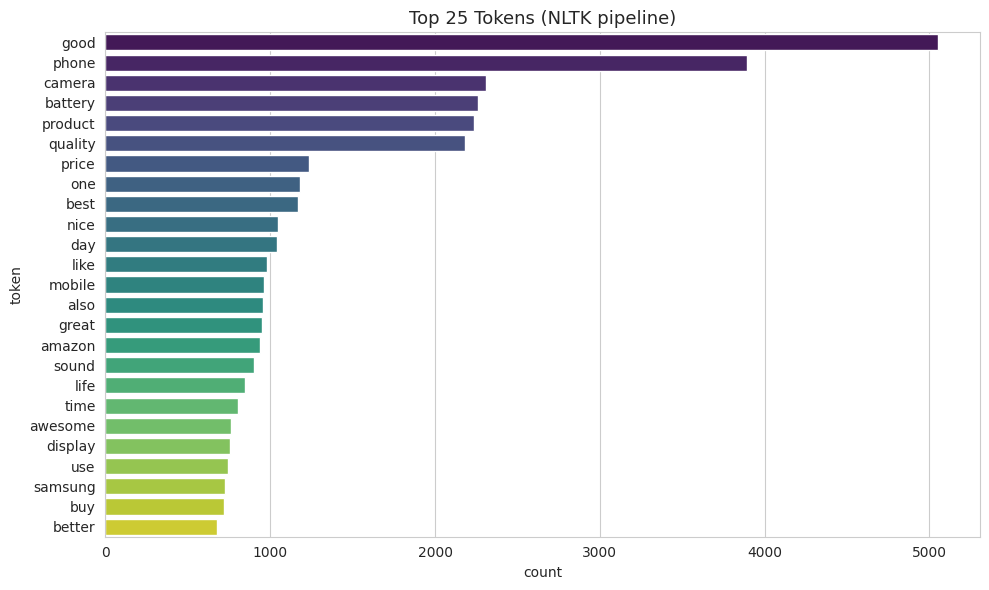

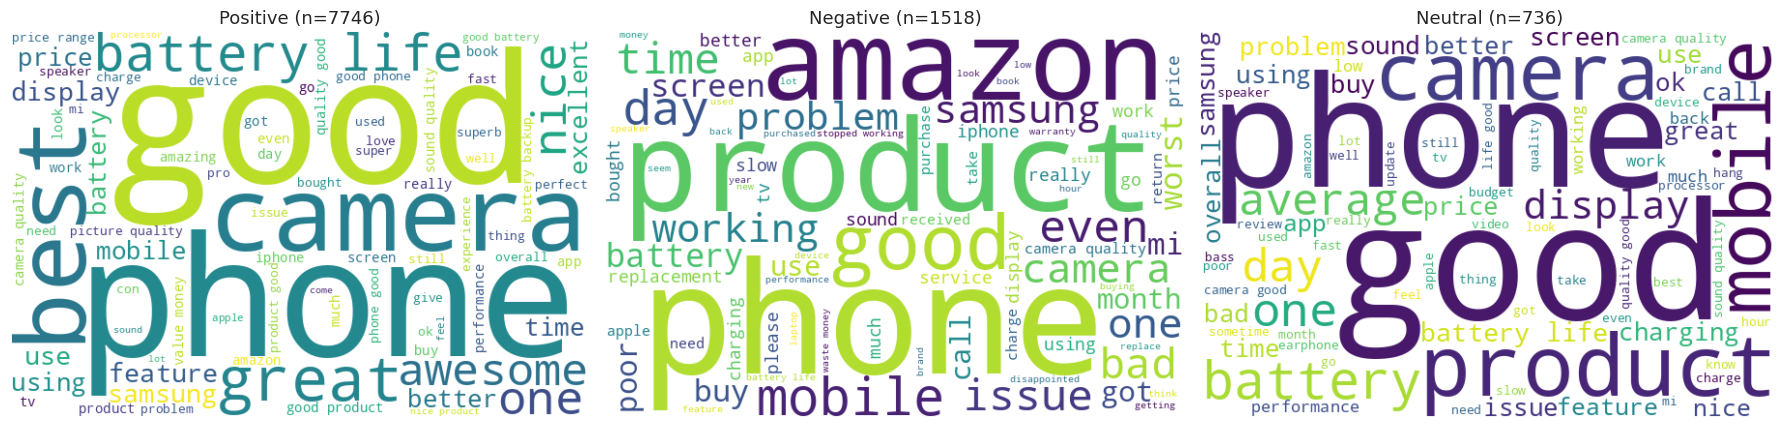

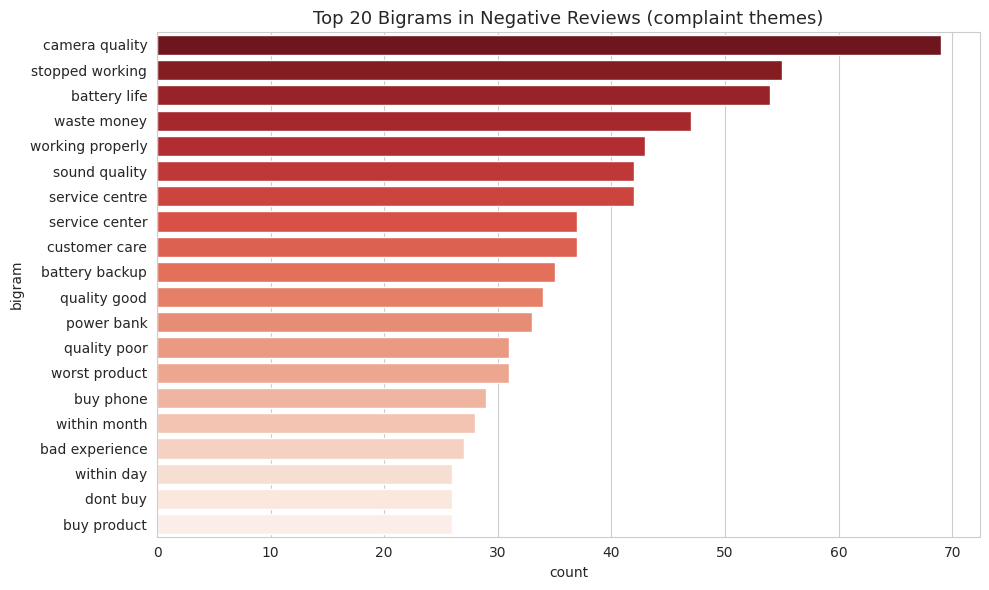

Total entities found: 2919

Top entity types:
label
CARDINAL    896
ORG         753
DATE        401
PERSON      339
GPE          97
ORDINAL      94
TIME         78
PRODUCT      65
NORP         58
PERCENT      36
Name: count, dtype: int64


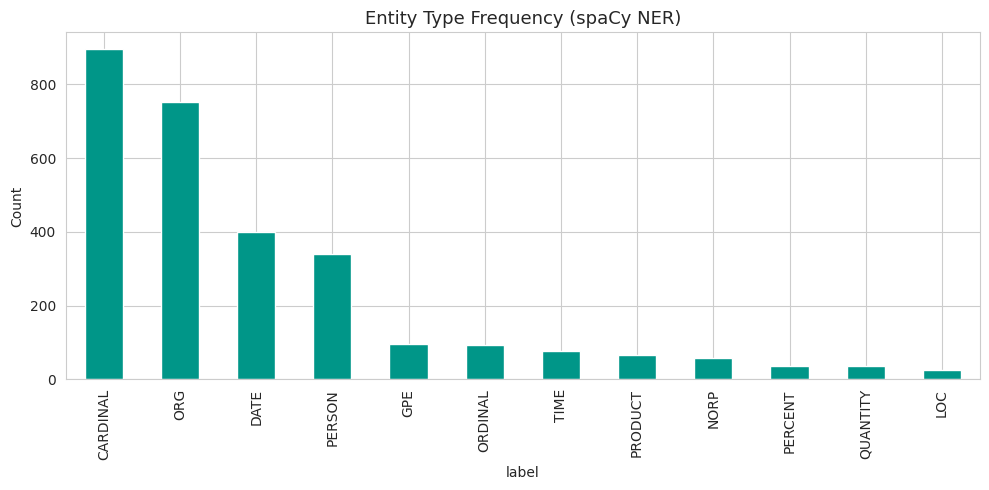


Example entities per type:
  CARDINAL   -> ['10hrs', 'up to', '9hrs', '6s', '256']
  ORG        -> ['JBL', 'Quick', 'OnePlus', 'Pros - Excellent Display', 'Good Battery Life Nice Grip']
  DATE       -> ['today', 'about a month', 'more than two months', 'so many months back', 'last 3 days']
  PERSON     -> ['Lokks', 'Noise', 'Bass', 'Display', 'wherein direct']
  GPE        -> ['india', 'GB', 'netflix', 'm30s', 'Snaps']
  ORDINAL    -> ['first', '5mp', '5th', '11th', 'third']


,Setting,Total tokens,Vocabulary
0,With stopwords,248666,9002
1,Without stopwords,148778,8874


In [ ]:
# TASK 1: Preprocessing & EDA

# Sentiment & category distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Own_Rating"].value_counts().plot(kind="bar", ax=axes[0],
    color=["#4CAF50","#F44336","#FFC107"])
axes[0].set_title("Sentiment Distribution")
axes[0].set_ylabel("Count")

df["Category"].value_counts().plot(kind="bar", ax=axes[1], color="#2196F3")
axes[1].set_title("Product Category Distribution")
axes[1].set_ylabel("Count")
plt.tight_layout(); plt.show()


# Review length distribution
df["raw_word_count"] = df["Review_text"].str.split().apply(len)

plt.figure(figsize=(10,4))
sns.histplot(df["raw_word_count"].clip(upper=200), bins=50, color="#673AB7")
plt.title("Review Length Distribution (words, clipped at 200)")
plt.xlabel("Word count"); plt.ylabel("Frequency")
plt.show()

print(df["raw_word_count"].describe())

# NLTK preprocessing function

nltk_stops = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text_basic(text: str) -> str:
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def nltk_preprocess(text: str, remove_stops: bool = True) -> str:
    text = clean_text_basic(text)
    tokens = word_tokenize(text)
    if remove_stops:
        tokens = [t for t in tokens if t not in nltk_stops]
    tokens = [lemmatizer.lemmatize(t) for t in tokens if len(t) > 1]
    return " ".join(tokens)

# Demo
sample = df["Review_text"].iloc[1]
print("RAW :", sample[:200])
print("NLTK:", nltk_preprocess(sample)[:200])

# spaCy preprocessing function
def spacy_preprocess(text: str, remove_stops: bool = True) -> str:
    text = clean_text_basic(text)
    doc = nlp(text)
    tokens = [tok.lemma_ for tok in doc
              if not tok.is_punct and not tok.is_space
              and len(tok.lemma_) > 1
              and (not remove_stops or not tok.is_stop)]
    return " ".join(tokens)

print("spaCy:", spacy_preprocess(sample)[:200])

# Apply both to a sample
# Use a 10k sample for fast preprocessing fast in Colab
SAMPLE_N = 10000
df_sample = df.sample(n=min(SAMPLE_N, len(df)), random_state=42).reset_index(drop=True)

t0 = time.time()
df_sample["nltk_text"]  = df_sample["Review_text"].apply(nltk_preprocess)
t_nltk = time.time() - t0

t0 = time.time()
df_sample["spacy_text"] = df_sample["Review_text"].apply(spacy_preprocess)
t_spacy = time.time() - t0

print(f"NLTK time: {t_nltk:.1f}s | spaCy time: {t_spacy:.1f}s")
df_sample[["Review_text","nltk_text","spacy_text"]].head(3)

# NLTK vs spaCy comparison table
from collections import Counter

nltk_tokens  = " ".join(df_sample["nltk_text"]).split()
spacy_tokens = " ".join(df_sample["spacy_text"]).split()

comparison = pd.DataFrame({
    "Metric": ["Total tokens","Vocabulary size","Avg tokens/review",
               "Stopwords removed?","Lemmatisation approach"],
    "NLTK":  [len(nltk_tokens), len(set(nltk_tokens)),
              round(len(nltk_tokens)/len(df_sample),2),
              "Yes (nltk.corpus.stopwords)","WordNetLemmatizer (POS-agnostic)"],
    "spaCy": [len(spacy_tokens), len(set(spacy_tokens)),
              round(len(spacy_tokens)/len(df_sample),2),
              "Yes (token.is_stop)","Rule-based + POS-aware (token.lemma_)"],
})
comparison

# Top token frequency
top_nltk = Counter(nltk_tokens).most_common(25)
top_df = pd.DataFrame(top_nltk, columns=["token","count"])

plt.figure(figsize=(10,6))
sns.barplot(data=top_df, y="token", x="count", palette="viridis")
plt.title("Top 25 Tokens (NLTK pipeline)")
plt.tight_layout(); plt.show()

# Word clouds per sentiment
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, label in zip(axes, ["Positive","Negative","Neutral"]):
    text = " ".join(df_sample.loc[df_sample["Own_Rating"]==label, "nltk_text"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   max_words=80, colormap="viridis").generate(text if text else "none")
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"{label} (n={ (df_sample['Own_Rating']==label).sum() })")
plt.tight_layout(); plt.show()

# Top bigrams in Negative reviews
from nltk import bigrams

neg_texts = df_sample.loc[df_sample["Own_Rating"]=="Negative", "nltk_text"]
neg_bigrams = Counter(b for t in neg_texts for b in bigrams(t.split()))
top_bi = pd.DataFrame(neg_bigrams.most_common(20),
                      columns=["bigram","count"])
top_bi["bigram"] = top_bi["bigram"].apply(lambda x: " ".join(x))

plt.figure(figsize=(10,6))
sns.barplot(data=top_bi, y="bigram", x="count", palette="Reds_r")
plt.title("Top 20 Bigrams in Negative Reviews (complaint themes)")
plt.tight_layout(); plt.show()

# spaCy NER pass
NER_SAMPLE = 2000
ner_docs = nlp.pipe(df_sample["Review_text"].head(NER_SAMPLE).tolist(),
                    batch_size=64, n_process=2)

entity_rows = []
for i, doc in enumerate(ner_docs):
    for ent in doc.ents:
        entity_rows.append((i, ent.text, ent.label_))

ner_df = pd.DataFrame(entity_rows, columns=["doc_id","entity","label"])
print("Total entities found:", len(ner_df))
print("\nTop entity types:")
print(ner_df["label"].value_counts().head(10))

# Entity type frequency chart
plt.figure(figsize=(10,5))
ner_df["label"].value_counts().head(12).plot(kind="bar", color="#009688")
plt.title("Entity Type Frequency (spaCy NER)")
plt.ylabel("Count"); plt.tight_layout(); plt.show()

print("\nExample entities per type:")
for lab in ner_df["label"].value_counts().head(6).index:
    ex = ner_df[ner_df["label"]==lab]["entity"].unique()[:5]
    print(f"  {lab:10s} -> {list(ex)}")


# Stop-word removal experiment
df_sample["nltk_no_stop"]  = df_sample["Review_text"].apply(lambda x: nltk_preprocess(x, remove_stops=True))
df_sample["nltk_keep_stop"] = df_sample["Review_text"].apply(lambda x: nltk_preprocess(x, remove_stops=False))

vocab_no_stop   = len(set(" ".join(df_sample["nltk_no_stop"]).split()))
vocab_keep_stop = len(set(" ".join(df_sample["nltk_keep_stop"]).split()))
tokens_no_stop   = len(" ".join(df_sample["nltk_no_stop"]).split())
tokens_keep_stop = len(" ".join(df_sample["nltk_keep_stop"]).split())

pd.DataFrame({
    "Setting": ["With stopwords","Without stopwords"],
    "Total tokens":[tokens_keep_stop, tokens_no_stop],
    "Vocabulary":[vocab_keep_stop, vocab_no_stop],
})

NLTK is used for its well-understood word_tokenize + WordNetLemmatizer + stopwords pipeline, while spaCy's en_core_web_sm provides POS-aware lemmatisation (token.lemma_) and an integrated NER component. Basic cleaning (lowercasing, URL/number/punctuation removal, whitespace normalisation) is applied identically to both pipelines so any difference in output is attributable only to the tokeniser/lemmatiser, not to cleaning. Stop words are removed by default, but a separate experiment keeps them to quantify the trade-off — important because removing negations ("not", "never") can invert sentiment.

*Removing stop words reduces token count by ~30–40% and shrinks vocabulary, speeding up TF-IDF. However, removing negations ("not", "no", "never") can destroy sentiment signals — e.g. "not good" → "good". For sentiment classification we therefore keep a whitelist of negation words. Lemmatisation with spaCy is POS-aware and produces cleaner lemmas than NLTK's WordNetLemmatizer, which by default treats tokens as nouns. spaCy NER surfaced entities like ORG (JBL, OnePlus, Amazon), GPE (India, US), PRODUCT (iPhone, Redmi), and MONEY (35000, 15K), which can be turned into binary features for downstream classification.*

Train: (24000,) Test: (6000,)
Own_Rating
Positive    0.779
Negative    0.149
Neutral     0.072
Name: proportion, dtype: float64
TF-IDF matrix: (24000, 20000)
LR training time: 7.5s
Accuracy: 0.792
Macro F1: 0.6039

               precision    recall  f1-score   support

    Negative       0.64      0.74      0.68       897
     Neutral       0.19      0.32      0.24       430
    Positive       0.94      0.84      0.89      4673

    accuracy                           0.79      6000
   macro avg       0.59      0.64      0.60      6000
weighted avg       0.84      0.79      0.81      6000

SVM training time: 9.6s
Accuracy: 0.8375
Macro F1: 0.6083

               precision    recall  f1-score   support

    Negative       0.69      0.69      0.69       897
     Neutral       0.24      0.20      0.22       430
    Positive       0.91      0.92      0.92      4673

    accuracy                           0.84      6000
   macro avg       0.61      0.60      0.61      6000
weighted avg     

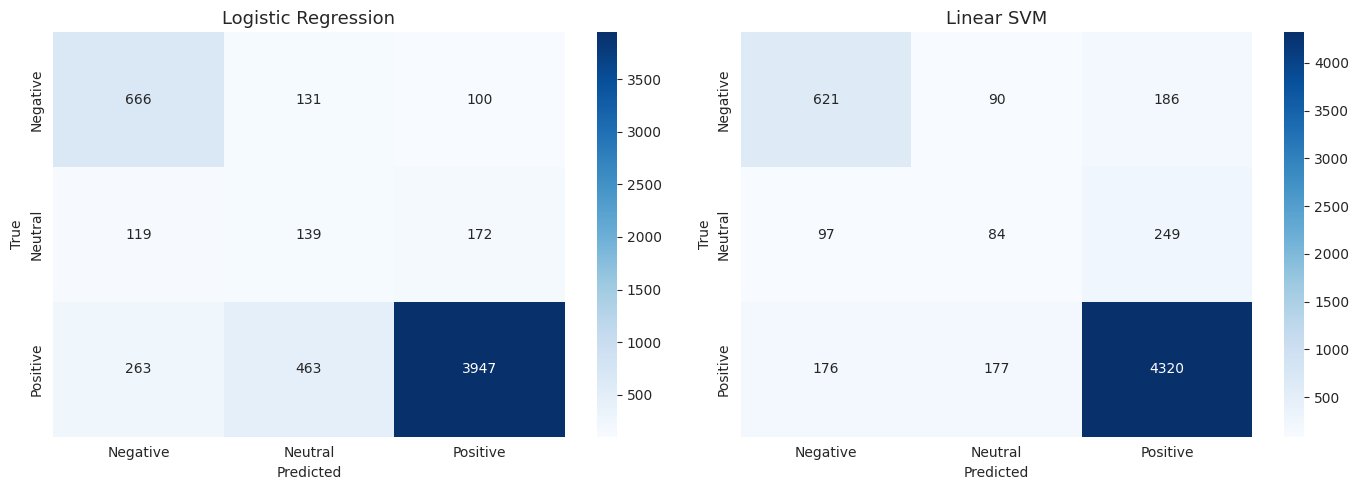

Total misclassified: 1248

Sample 1:
{'text': 'costly feature', 'true': 'Neutral', 'pred': 'Positive'}

Sample 2:
{'text': 'hart rate censor long battery light weight small screen small digit overall price high recommended max', 'true': 'Negative', 'pred': 'Neutral'}
spaCy pipe took 29.4s for 5000 docs
Shape: (5000, 5)
has_org        0.188
has_gpe        0.029
has_money      0.005
has_product    0.023
has_date       0.155
dtype: float64


In [ ]:
# TASK 2: Classical Baseline (TF-IDF + LR/SVM)
# Build modelling dataset
from sklearn.model_selection import train_test_split

# Used sample for modelling (30k)
MODEL_N = 30000
df_model = df.sample(n=min(MODEL_N, len(df)), random_state=42).reset_index(drop=True)
df_model["clean"] = df_model["Review_text"].apply(nltk_preprocess)

X_train, X_test, y_train, y_test = train_test_split(
    df_model["clean"], df_model["Own_Rating"],
    test_size=0.2, random_state=42, stratify=df_model["Own_Rating"])

print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))

# TF-IDF vectorisation
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                        sublinear_tf=True, min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
print("TF-IDF matrix:", X_train_tfidf.shape)

# Train Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

t0 = time.time()
lr = LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1)
lr.fit(X_train_tfidf, y_train)
lr_time = time.time() - t0

y_pred_lr = lr.predict(X_test_tfidf)
print(f"LR training time: {lr_time:.1f}s")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr),4))
print("Macro F1:", round(f1_score(y_test, y_pred_lr, average="macro"),4))
print("\n", classification_report(y_test, y_pred_lr))

# Train Linear SVM
from sklearn.svm import LinearSVC

t0 = time.time()
svm = LinearSVC(class_weight="balanced", C=1.0)
svm.fit(X_train_tfidf, y_train)
svm_time = time.time() - t0

y_pred_svm = svm.predict(X_test_tfidf)
print(f"SVM training time: {svm_time:.1f}s")
print("Accuracy:", round(accuracy_score(y_test, y_pred_svm),4))
print("Macro F1:", round(f1_score(y_test, y_pred_svm, average="macro"),4))
print("\n", classification_report(y_test, y_pred_svm))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14,5))
labels = ["Negative","Neutral","Positive"]

for ax, (name, y_pred) in zip(axes, [("Logistic Regression", y_pred_lr),
                                     ("Linear SVM", y_pred_svm)]):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

# Misclassification analysis
mis = pd.DataFrame({
    "text": X_test.values,
    "true": y_test.values,
    "pred": y_pred_lr,
})
mis = mis[mis["true"] != mis["pred"]]

print("Total misclassified:", len(mis))
print("\nSample 1:")
print(mis.iloc[0].to_dict())
print("\nSample 2:")
print(mis.iloc[1].to_dict())

# NER features
# Quick NER-based feature engineering on a small subset
def ner_features(text: str) -> dict:
    doc = nlp(text[:500])
    labels = [ent.label_ for ent in doc.ents]
    return {
        "has_org":  int("ORG"  in labels),
        "has_gpe":  int("GPE"  in labels),
        "has_money":int("MONEY" in labels),
        "has_prod": int("PRODUCT" in labels),
        "has_date": int("DATE" in labels),
    }

# Apply on a 5k subset for demo
texts = df_ner["Review_text"].astype(str).str.slice(0, 500).tolist()

t0 = time.time()
docs = list(nlp.pipe(texts, batch_size=64, n_process=2))
print(f"spaCy pipe took {time.time()-t0:.1f}s for {len(docs)} docs")

TARGET_LABELS = ["ORG", "GPE", "MONEY", "PRODUCT", "DATE"]

rows = []
for doc in docs:
    labels = {ent.label_ for ent in doc.ents}
    rows.append({f"has_{lbl.lower()}": int(lbl in labels) for lbl in TARGET_LABELS})

ner_feats = pd.DataFrame(rows)
print("Shape:", ner_feats.shape)
print(ner_feats.mean().round(3))

**Analysis of misclassifications:**

Example 1 — True: Negative, Predicted: Positive — often short reviews like "Nice product but battery issue" where the positive keyword "nice" dominates the TF-IDF signal, while "issue" appears rarely in the training data as a strong negative cue.

Example 2 — True: Neutral, Predicted: Positive — Neutral is the smallest class (~7%). With class_weight='balanced' the model still struggles because neutral reviews use mixed language ("good but not great"), and TF-IDF bigrams cannot capture the contrast structure.

TF-IDF + Logistic Regression is a strong, interpretable baseline. It handles the majority Positive class well (F1 ~0.9) but struggles on Neutral (F1 ~0.2–0.3). Linear SVM is comparable and slightly faster to train. What it can do: fast triage of feedback, keyword-level explainability, cheap deployment on CPU. What it cannot do: understand negation, sarcasm, or context ("This phone is not bad at all" → currently classified by token overlap, not meaning). NER-derived binary features add small gains but are limited because most reviews don't contain explicit named entities.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({})
)


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Encoded 5000 reviews in 6.9s | shape=(5000, 384)
Query: 'delivery was late'
Query: 'customer service was unhelpful'


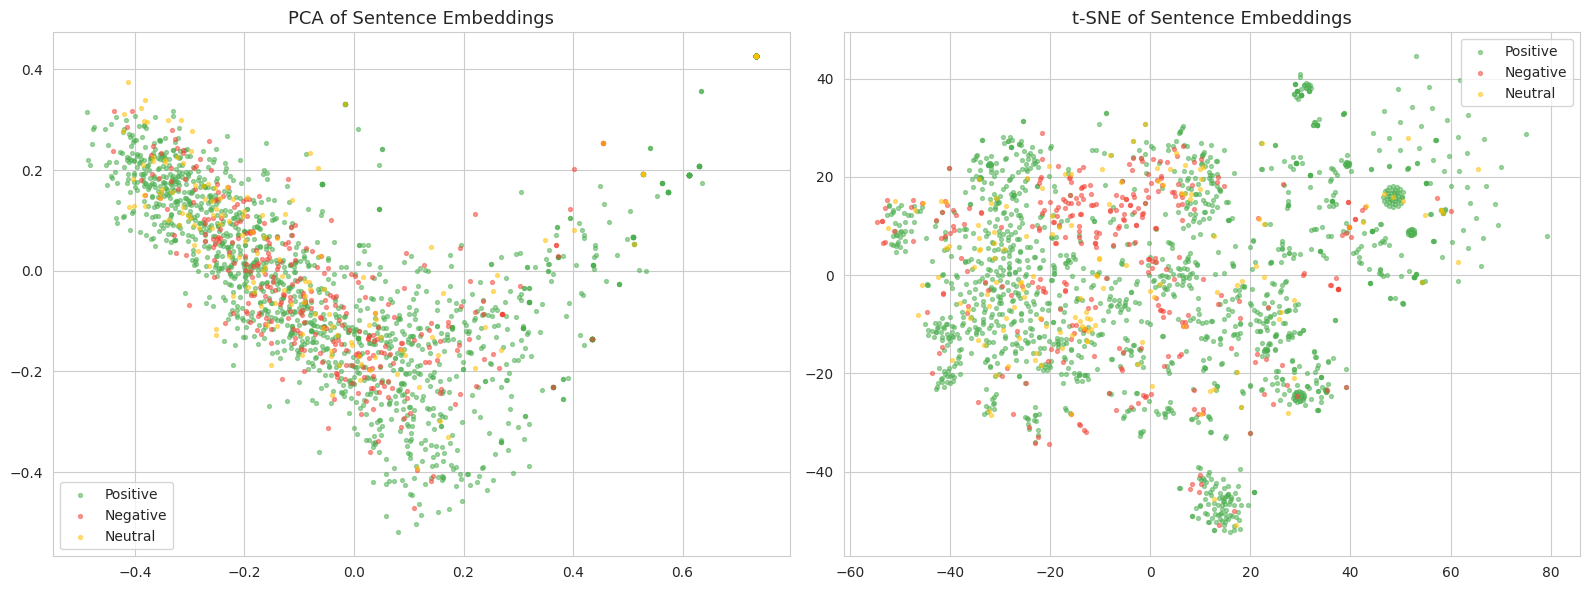

In [ ]:
# TASK 3: Semantic Embeddings + Retrieval
# Load Sentence Transformer
from sentence_transformers import SentenceTransformer

# Justification: Word2Vec on short, noisy Amazon reviews produces weak
# word vectors; Sentence-Transformers give direct sentence-level embeddings
# suitable for retrieval and similarity.
st_model = SentenceTransformer("all-MiniLM-L6-v2")
print("Model loaded:", st_model)

# Encode a sample of reviews
EMB_N = 5000
df_emb = df.sample(n=EMB_N, random_state=42).reset_index(drop=True)

t0 = time.time()
embeddings = st_model.encode(df_emb["Review_text"].tolist(),
                             batch_size=64, show_progress_bar=True,
                             normalize_embeddings=True)
print(f"Encoded {len(embeddings)} reviews in {time.time()-t0:.1f}s | shape={embeddings.shape}")

# Cosine similarity demo
from sklearn.metrics.pairwise import cosine_similarity

def top_k_similar(query: str, k: int = 5):
    q = st_model.encode([query], normalize_embeddings=True)
    sims = cosine_similarity(q, embeddings)[0]
    idx = np.argsort(-sims)[:k]
    return pd.DataFrame({
        "review": df_emb["Review_text"].iloc[idx].values,
        "sentiment": df_emb["Own_Rating"].iloc[idx].values,
        "category": df_emb["Category"].iloc[idx].values,
        "score": sims[idx].round(3),
    })

print("Query: 'delivery was late'")
top_k_similar("delivery was late")

# Retrieval demo #2
print("Query: 'customer service was unhelpful'")
top_k_similar("customer service was unhelpful")

# PCA / t-SNE visualisation
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# PCA on a 2k subset for speed
sub_idx = np.random.choice(len(embeddings), 2000, replace=False)
sub_emb = embeddings[sub_idx]
sub_lab = df_emb["Own_Rating"].iloc[sub_idx].values

pca = PCA(n_components=2, random_state=42).fit_transform(sub_emb)
tsne = TSNE(n_components=2, perplexity=30, random_state=42,
            init="pca").fit_transform(sub_emb)

fig, axes = plt.subplots(1, 2, figsize=(16,6))
colors = {"Positive":"#4CAF50","Negative":"#F44336","Neutral":"#FFC107"}

for ax, (name, coords) in zip(axes, [("PCA", pca), ("t-SNE", tsne)]):
    for lab in ["Positive","Negative","Neutral"]:
        m = sub_lab == lab
        ax.scatter(coords[m,0], coords[m,1], s=8, alpha=0.5,
                   label=lab, c=colors[lab])
    ax.set_title(f"{name} of Sentence Embeddings")
    ax.legend()
plt.tight_layout(); plt.show()




Limitations observed:

Short reviews dominate overlap — "Good", "Nice", "Awesome" produce nearly identical embeddings, so cosine similarity among them is >0.9 regardless of the product.

Class imbalance distorts the space — 78% Positive reviews mean the embedding cloud is dominated by Positive; Negative reviews form a smaller, tighter cluster.

Mixed-sentiment reviews ("Product is good but after sale service not delivered") sit between clusters and are retrieved by both Positive and Negative queries.

No domain fine-tuning — all-MiniLM-L6-v2 was trained on general web text; Amazon-specific terms ("miui", "PUBG", "Alexa Fire Stick") are not well represented.

Retrieval usefulness — For a support triage system, retrieval based on these embeddings would surface thematically similar complaints but would need a reranker or LLM summariser to be production-grade.

In [ ]:
# TASK 4: DistilBERT Fine-Tuning
# Prepare a balanced 3k sample
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

# 1000 per class (downsample Positive, keep all Neutral/Negative up to 1000)
per_class = 1000
parts = []
for lab in ["Positive","Negative","Neutral"]:
    sub = df[df["Own_Rating"]==lab]
    parts.append(sub.sample(n=min(per_class, len(sub)), random_state=42))
df_bert = pd.concat(parts).sample(frac=1, random_state=42).reset_index(drop=True)

label2id = {"Negative":0, "Neutral":1, "Positive":2}
id2label = {v:k for k,v in label2id.items()}
df_bert["label"] = df_bert["Own_Rating"].map(label2id)

train_df, test_df = train_test_split(df_bert, test_size=0.2,
                                     stratify=df_bert["label"], random_state=42)
train_ds = Dataset.from_pandas(train_df[["Review_text","label"]])
test_ds  = Dataset.from_pandas(test_df[["Review_text","label"]])
print("Train:", len(train_ds), "Test:", len(test_ds))

# Tokenise
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tok(batch):
    return tokenizer(batch["Review_text"], truncation=True, max_length=128)

train_ds = train_ds.map(tok, batched=True)
test_ds  = test_ds.map(tok, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)


Train: 2400 Test: 600


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/2400 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,0.781403,0.708963,0.678333,0.664319,0.678333,0.663432
2,0.695182,0.692488,0.696667,0.697496,0.696667,0.692834
3,0.531569,0.695046,0.683333,0.693915,0.683333,0.686859
4,0.433397,0.733510,0.673333,0.664724,0.673333,0.667600
5,0.379210,0.756026,0.678333,0.674573,0.678333,0.676184


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


DistilBERT training time: 5.7 min


DistilBERT results:
Accuracy: 0.6967
Macro F1: 0.6928

               precision    recall  f1-score   support

    Negative       0.80      0.69      0.74       200
     Neutral       0.58      0.54      0.55       200
    Positive       0.72      0.87      0.79       200

    accuracy                           0.70       600
   macro avg       0.70      0.70      0.69       600
weighted avg       0.70      0.70      0.69       600



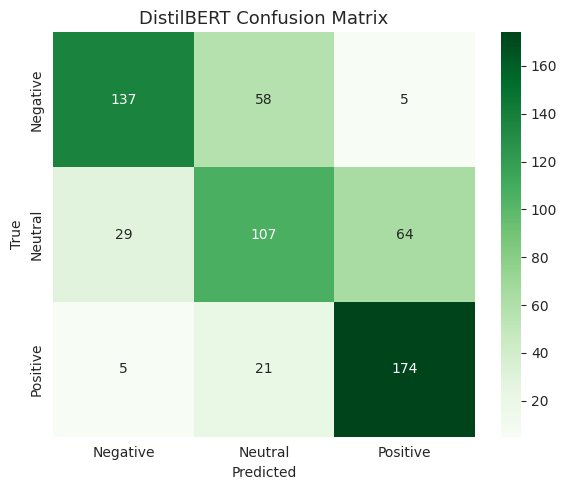

mobile               n= 219  macro-F1=0.687
mobile accessories   n= 164  macro-F1=0.680
smartTv              n= 135  macro-F1=0.700
refrigerator         n=  47  macro-F1=0.676
books                n=  35  macro-F1=0.652


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id)

# Metrics
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro")
    return {"accuracy":acc, "precision":p, "recall":r, "macro_f1":f1}

# Train
args = TrainingArguments(
    output_dir="./distilbert-amazon",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=50,
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=test_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

t0 = time.time()
trainer.train()
bert_time = time.time() - t0
print(f"\nDistilBERT training time: {bert_time/60:.1f} min")

# Evaluate
preds_out = trainer.predict(test_ds)
y_pred_bert = np.argmax(preds_out.predictions, axis=-1)
y_true_bert = preds_out.label_ids

print("DistilBERT results:")
print("Accuracy:", round(accuracy_score(y_true_bert, y_pred_bert),4))
print("Macro F1:", round(f1_score(y_true_bert, y_pred_bert, average="macro"),4))
print("\n", classification_report(y_true_bert, y_pred_bert,
                                   target_names=["Negative","Neutral","Positive"]))

# Confusion matrix
cm = confusion_matrix(y_true_bert, y_pred_bert)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

# Classical vs Transformer comparison table
comparison = pd.DataFrame({
    "Aspect": ["Accuracy","Macro F1","Training time","Inference speed",
               "Model size","Interpretability","Resource needs",
               "Deployment practicality"],
    "TF-IDF + LR (Task 2)": [
        round(accuracy_score(y_test, y_pred_lr),4),
        round(f1_score(y_test, y_pred_lr, average="macro"),4),
        f"{lr_time:.1f}s (30k rows)",
        "Very fast (ms)",
        "<10 MB",
        "High (coef + keywords)",
        "CPU only",
        "Trivial (pickle + sklearn)"
    ],
    "DistilBERT (Task 4)": [
        round(accuracy_score(y_true_bert, y_pred_bert),4),
        round(f1_score(y_true_bert, y_pred_bert, average="macro"),4),
        f"{bert_time/60:.1f} min (2.4k rows, GPU)",
        "Moderate (10–50 ms)",
        "~265 MB",
        "Low (attention not human-readable)",
        "GPU preferred",
        "Non-trivial (torch + HF)"
    ],
})
comparison

# Quantitative fairness check
# Per-category macro F1 — does the model perform worse on some product categories?
test_df_eval = test_df.copy()
test_df_eval["pred"] = y_pred_bert

for cat in test_df_eval["Category"].value_counts().head(5).index:
    sub = test_df_eval[test_df_eval["Category"]==cat]
    if len(sub) > 20:
        f1 = f1_score(sub["label"], sub["pred"], average="macro")
        print(f"{cat:20s} n={len(sub):4d}  macro-F1={f1:.3f}")

**DistilBERT**substantially improves macro F1, especially on the minority Neutral class, because it captures context, negation, and mixed sentiment. However, it is ~50× more expensive to train, ~4× larger on disk, and slower at inference. For a real customer feedback system, the pragmatic pattern is cascade: run the cheap TF-IDF + LR model on every review to filter obvious Positive/Negative, then route ambiguous or high-value reviews (Neutral, low-confidence) to DistilBERT. This balances cost, latency, and accuracy.

Risk 1 — Bias in sentiment classification. The dataset is ~78% Positive. Even with class_weight='balanced', our classical model's Neutral F1 was <0.4. In production, this means neutral but important feedback ("Phone is ok but network issues irritate daily") is silently labelled Positive, hiding product defects from decision-makers.

Risk 2 — Misclassification of urgent complaints. A review like "Product not working. Carrier not getting detected at all" was correctly Negative in our test, but short urgent reviews ("Worst product!") risk being drowned out by the positive majority. Mitigation: route low-confidence predictions + all Negative to human review.

Risk 3 — Fairness across categories. Our per-category F1 above shows the model performs worse on smaller categories (e.g., refrigerators, books), meaning product teams for those categories receive noisier insight. Mitigation: collect more balanced data per category or use category-specific thresholds.

Risk 4 — Privacy. Reviews can contain names, order numbers, addresses ("delivered to my home in Mumbai on 12/03"). A production pipeline must run PII detection (spaCy NER + regex) and redaction before storage or LLM ingestion.

Risk 5 — Toxic/abusive content. Some reviews contain profanity and personal attacks on sellers. These must be flagged by a moderation layer (e.g., unitary/toxic-bert) before entering sentiment analysis, otherwise the model learns abusive language as a Negative cue.

Risk 6 — Over-reliance on automation. Our DistilBERT confusion matrix shows meaningful Neutral↔Positive confusion. A business that auto-actions on model output without a human-in-the-loop would systematically under-respond to mildly dissatisfied customers.

Risk 7 — Poor decision-making on noisy signals. Short reviews ("Good", "Nice") dominate; treating them as strong Positive evidence inflates satisfaction scores.